# Titanic Survival: Ensemble Learning

**Author:** Mohammed Alaa Eddine GUERBOUZ  
**University:** University of Ghardaia — Department of Mathematics and Computer Science  
**Academic period:** Master 2 SIEC · 2024–2025  
**Type:** Original university coursework, reorganized for a GitHub portfolio in 2026

**Problem:** Model survival outcome with combinations of tree-based learners.

**Approach:** Pandas-based preparation and ensemble learning comparisons.

> Historical coursework: the computational cells below are retained from the original submission. Results have not been independently rerun or revalidated as part of the portfolio reorganization. See this folder's README for data and execution notes.


---

<div class="alert alert-success">

<center><b>University of Ghardaia</b></center>
    
<center><i>Faculty of Science and Technology - Department of Mathematics and Computer Science – Master 2 SIEC - 2024/2025</i>
</center></div>

------

<br><br>

<center>
<span style='font-weight:bold;font-size:27px;'><span style='color:#5D00FF;'>Mini Projet 1 : Ensamble Learning  </span>
    </span>
    </center>
<br>


### GUERBOUZ MOHAMMED ALAA EDDINE

### Step 1: Import Libraries
First, we need to import the necessary libraries for data analysis, visualization, and machine learning.

In [17]:
# Import necessary libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

pandas and numpy are used for data manipulation.

seaborn and matplotlib are used for data visualization.

train_test_split is used to split the dataset into training and testing sets.

RandomForestClassifier is the ensemble learning model we will use.

accuracy_score, confusion_matrix, and classification_report are used to evaluate the model.

### Step 2: Load the Dataset

In this step, we load the Titanic dataset from a URL (or a local file if you have it downloaded). The dataset contains information about the passengers on the Titanic, including whether they survived or not, their age, gender, class, etc.

- We use `pandas.read_csv()` to load the dataset into a DataFrame.
- `df.head()` is used to display the first 5 rows of the dataset, giving us a quick overview of the data structure.

This step is crucial for understanding the dataset and preparing it for further analysis..

In [18]:
# Load the Titanic dataset
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

# Display the first few rows of the dataset
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Explanation:

We load the dataset from a URL (you can also load it from a local file if you have it downloaded).

df.head() displays the first 5 rows of the dataset to get a quick overview.

### Step 3: Data Exploration and Preprocessing

In this step, we explore the dataset and handle any missing or incomplete data:

1. **Check for Missing Values**:
   - We use `df.isnull().sum()` to identify columns with missing values.
   - Missing values can negatively impact the model's performance, so we need to handle them.

2. **Handle Missing Values**:
   - For the `Age` column, we fill missing values with the median age.
   - For the `Embarked` column, we fill missing values with the most common value (mode).
   - We drop the `Cabin` column because it has too many missing values, making it unreliable for analysis.

3. **Convert Categorical Variables**:
   - We convert categorical variables like `Sex` and `Embarked` into numerical values using mapping. This is necessary because machine learning models require numerical input.

4. **Display the Preprocessed Dataset**:
   - After handling missing values and converting categorical variables, we display the dataset again using `df.head()` to ensure the changes have been applied correctly.

This step ensures that the dataset is clean and ready for modeling..

In [19]:
# Check for missing values
df.isnull().sum()

# Handle missing values
# Fill missing 'Age' with the median value
df['Age'].fillna(df['Age'].median(), inplace=True)

# Fill missing 'Embarked' with the most common value
df['Embarked'].fillna(df['Embarked'].mode()[0], inplace=True)

# Drop the 'Cabin' column as it has too many missing values
df.drop('Cabin', axis=1, inplace=True)

# Convert categorical variables into numerical ones
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})
df['Embarked'] = df['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})

# Display the dataset after preprocessing
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",0,22.0,1,0,A/5 21171,7.2500,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,1,0,PC 17599,71.2833,1
2,3,1,3,"Heikkinen, Miss. Laina",1,26.0,0,0,STON/O2. 3101282,7.9250,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,1,0,113803,53.1000,0
4,5,0,3,"Allen, Mr. William Henry",0,35.0,0,0,373450,8.0500,0


Explanation:

We check for missing values in the dataset using isnull().sum().

We fill missing values in the Age column with the median value and in the Embarked column with the most common value.

We drop the Cabin column because it has too many missing values.

We convert categorical variables (Sex and Embarked) into numerical values using mapping.

### Step 4: Feature Selection and Correlation Analysis

In this step, we select the relevant features for the model and analyze the correlations between them:

1. **Feature Selection**:
   - We select features like `Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare`, and `Embarked` as they are likely to influence survival.
   - These features are stored in `X`, while the target variable (`Survived`) is stored in `y`.

2. **Correlation Analysis**:
   - We plot a correlation matrix using `seaborn.heatmap()` to visualize the relationships between the features.
   - The correlation matrix helps us understand which features are strongly related to each other and to the target variable.

This step helps us identify the most important features for predicting survival..

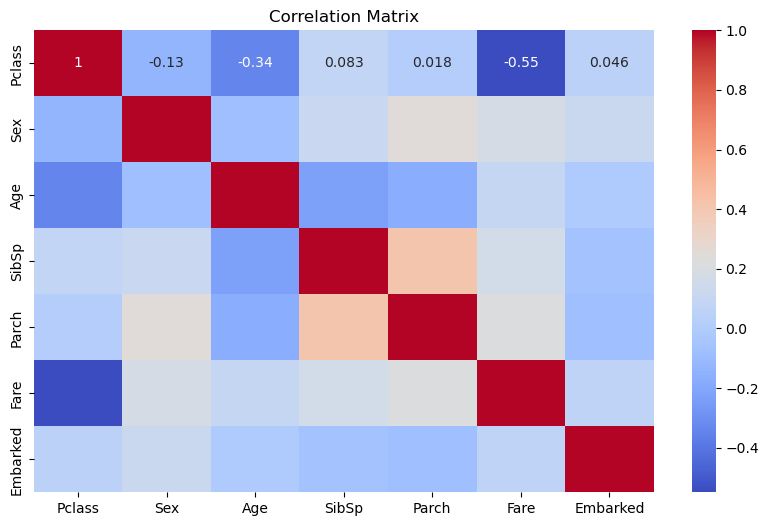

In [20]:
# Select relevant features for the model
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
X = df[features]
y = df['Survived']

# Plot correlation matrix
plt.figure(figsize=(10, 6))
sns.heatmap(X.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

Explanation:

We select the features that are relevant for predicting survival (Pclass, Sex, Age, SibSp, Parch, Fare, Embarked).

We plot a correlation matrix to understand the relationships between the features.

### Step 5: Split the Dataset into Training and Testing Sets

In this step, we split the dataset into training and testing sets:

- We use `train_test_split()` to divide the dataset into 80% training data and 20% testing data.
- The `random_state=42` parameter ensures that the split is reproducible, meaning you will get the same split every time you run the code.
- We print the shapes of the training and testing sets to confirm the split.

This step is essential for training the model on one portion of the data and evaluating it on another..

In [21]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Display the shape of the training and testing sets
print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (712, 7)
Testing set shape: (179, 7)


Explanation:

We split the dataset into 80% training and 20% testing sets using train_test_split.

random_state=42 ensures that the split is reproducible.

### Step 6: Train the Random Forest Model

In this step, we train a Random Forest classifier on the training data:

1. **Initialize the Model**:
   - We use `RandomForestClassifier()` with `n_estimators=100`, which means the model will use 100 decision trees.
   - The `random_state=42` parameter ensures reproducibility.

2. **Train the Model**:
   - We train the model using the training data (`X_train`, `y_train`) with the `fit()` method.

3. **Make Predictions**:
   - We use the trained model to make predictions on the test set (`X_test`) using the `predict()` method.

This step is where the model learns from the data and prepares to make predictions..

In [22]:
# Initialize the Random Forest classifier
model = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the model
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

Explanation:

We initialize a RandomForestClassifier with 100 trees (n_estimators=100).

We train the model using the training data (X_train, y_train).

We make predictions on the test set (X_test).



### Step 7: Evaluate the Model

In this step, we evaluate the performance of the Random Forest model:

1. **Calculate Accuracy**:
   - We use `accuracy_score()` to calculate the accuracy of the model's predictions on the test set.
   - Accuracy is the percentage of correct predictions out of all predictions.

2. **Confusion Matrix**:
   - We plot a confusion matrix using `seaborn.heatmap()` to visualize the true vs. predicted values.
   - The confusion matrix shows how many predictions were correct and how many were incorrect.

3. **Classification Report**:
   - We print a classification report using `classification_report()`, which includes precision, recall, and F1-score.
   - These metrics provide a more detailed evaluation of the model's performance.

This step helps us understand how well the model is performing and where it might need improvement..

Accuracy: 0.8268156424581006


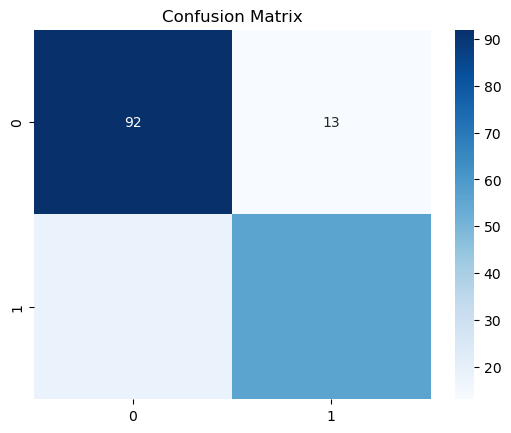

Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.88      0.86       105
           1       0.81      0.76      0.78        74

    accuracy                           0.83       179
   macro avg       0.82      0.82      0.82       179
weighted avg       0.83      0.83      0.83       179



In [23]:
# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

# Confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

# Classification report
print("Classification Report:\n", classification_report(y_test, y_pred))

Explanation:

We calculate the accuracy of the model using accuracy_score.

We plot a confusion matrix to visualize the true vs. predicted values.

We print a classification report that includes precision, recall, and F1-score.

### Step 8: Conclusion

In this step, we summarize the results of the model:

- We print the accuracy of the model as a percentataset.

In [24]:
# Conclusion
print("The Random Forest model achieved an accuracy of {:.2f}%.".format(accuracy * 100))

The Random Forest model achieved an accuracy of 82.68%.
